# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YosraHilmi/Fly-Rank-Internship/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. CTR / Engagement Opportunity Scoring

I chose the [CTR / Engagement Opportunity Scoring] lane because I’m interested in understanding user behavior, not just search rankings. Ranking makes a page visible, but CTR determines whether users actually click on it. If a page already receives many impressions but has a low CTR, I see it as an opportunity to increase traffic by improving click-through performance rather than rewriting the content.

## 2. The question: decision, action, cost of a wrong call

My work focuses on identifying pages with high visibility but low CTR and helping prioritize Which high-impression, low-CTR pages should be optimized first?.
It will benefit the SEO, marketing, and content teams by helping them decide which pages should be optimized first.
A wrong recommendation would waste the team's time and effort while missing opportunities to increase traffic and potential business value.

## 3. Quick look at the data


In [32]:
import pandas as pd

url = "https://raw.githubusercontent.com/YosraHilmi/Fly-Rank-Internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)

df["impressions_90d"].corr(df["ctr"])

np.float64(-0.01894973657977031)

the first thing that i noticed There is almost no linear correlation between impressions and CTR (r = -0.019), suggesting that impression volume alone does not explain click-through rate.

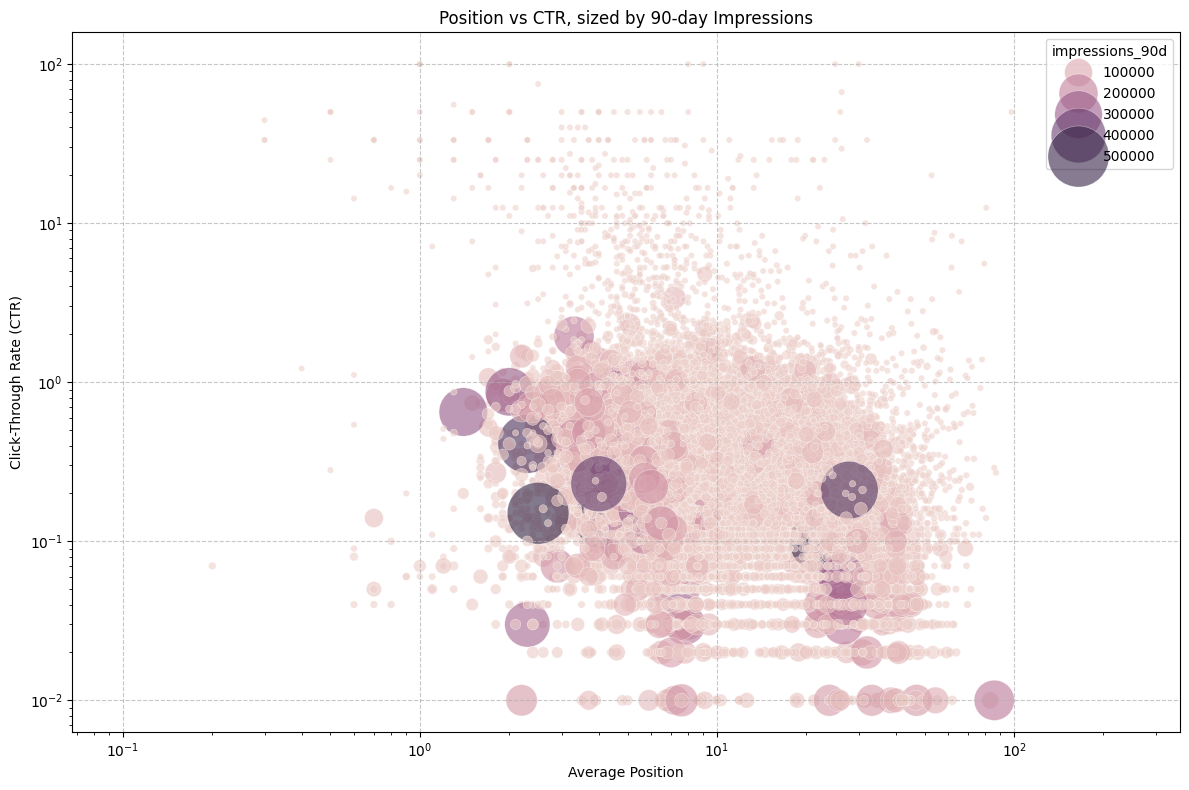

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the scatter plot
fig = plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df,
    x='avg_position',
    y='ctr',
    size='impressions_90d', # Size points by impressions
    hue='impressions_90d', # Color points by impressions (optional, for better visual distinction)
    sizes=(20, 2000), # Define the range of sizes for the points
    alpha=0.6, # Make points slightly transparent to see overlaps
    legend='brief' # Show a brief legend for the size
)

plt.title('Position vs CTR, sized by 90-day Impressions')
plt.xlabel('Average Position')
plt.ylabel('Click-Through Rate (CTR)')
plt.xscale('log') # Use a log scale for average position if values are highly skewed
plt.yscale('log') # Use a log scale for CTR if values are highly skewed
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The scatter plot shows that many pages receive high numbers of impressions while still having low CTR. These pages represent potential opportunities for optimization because increasing their CTR could generate more traffic without improving their search ranking.

In [31]:
# Calculate the median values for 'impressions_90d' and 'ctr'
median_impressions = df['impressions_90d'].median()
median_ctr = df['ctr'].median()

print(f"Median 'impressions_90d': {median_impressions:.2f}")
print(f"Median 'ctr': {median_ctr:.4f}")

# Identify pages with impressions_90d greater than the median and ctr lower than the median
opportunity_pages = df[
    (df['impressions_90d'] > median_impressions) &
    (df['ctr'] < median_ctr)
]

# Count the number of such pages
count_opportunity_pages = len(opportunity_pages)

# Calculate the percentage of such pages relative to all pages
percentage_opportunity_pages = (count_opportunity_pages / len(df)) * 100

print(f"\nNumber of pages with high impressions and low CTR: {count_opportunity_pages}")
print(f"Percentage of all pages: {percentage_opportunity_pages:.2f}%")

Median 'impressions_90d': 731.00
Median 'ctr': 0.0700

Number of pages with high impressions and low CTR: 3309
Percentage of all pages: 11.03%


These pages already receive substantial visibility but attract relatively few clicks. This suggests that they may represent valuable opportunities for CTR optimization without requiring improvements in search ranking.

## 4. Careful words: what I can and can't claim

in the next weeks, i hope my work will be eable to predict the best pages opportunities to enhance thier trafic and to rate them by score to help decision support in the company and saving time and effort, this work will never predect how google algorithm work or proof an undeniable fact, The work will involve reading and analyzing the data, and uncovering patterns that will assist us in our mission.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.